# Introducción a la Ingeniería de Datos

## Trabajo Práctico N.º 4
### Detección de eventos atípicos en el flujo de noticias de GDELT 2.0

**Autor:** Matías R. Pretel

## Instrucciones de la actividad

**Trabajo práctico 4**

**IMPORTANTE:** Al utilizar herramientas de inteligencia artificial deben indicar qué IA están usando y con qué propósito. Por ejemplo: "Claude Opus 4.6" para "mejorar redacción de textos" o "Chat GPT 5.6" para "crear código fuente".

Debe presentar una guía de instrucciones que permita reproducir lo mas fiel posible la información generada mediante inteligencia artificial. Esta guía debe demostrar la capacidad del estudiante para dirigir a la herramienta en al creación del resultado obtenido (Human-in-the-loop). Se espera que las instrucciones incluyan el vocabulario especifico del curso.

No se aceptan instrucciones que sean una copia directa de los enunciados de actividades.

**Introducción:**

En el TP1 procesaron el flujo de datos de GDELT 2.0. En el TP2 crearon un diseño de almacén de datos estructurado de forma tal que permita responder preguntas clave del negocio periodístico. En el TP3 analizaron el comportamiento multivariante del ecosistema global de noticias. En este ultimo TP, su tarea es encontrar eventos "raros" que valga la pena investigar.

**Recursos:**

- Lista de URLs con actualizaciones cada 15 minutos https://data.gdeltproject.org/gdeltv2/masterfilelist.txt .
- URL oficial del libro de códigos de GDELT 2.0 https://data.gdeltproject.org/documentation/GDELT-Event_Codebook-V2.0.pdf
- URL de la documentación en texto/HTML donde se enuncian los campos https://gdeltproject.org/data/documentation/CAMEO.Manual.1.1b3.pdf

**Actividades:**

1) **Ingesta de datos:** Extraigan las tablas de evento de 15 minutos de los últimos 7 días y armen una tabla desnormalizada (One Big Table). Guarden el resultado en formato parquet.

2) **Limpieza:**
   - **Nulos y ceros:** Identifiquen los datos faltantes (nulos o ceros). Descarten o imputen los valores faltantes indicando el criterio utilizado.
   - **Reducción de Cardinalidad:** Agrupen las categorías marginales (frecuencia menor al 5% de la muestra) bajo la etiqueta 'OTHER' antes de codificar.
   - **Codifiquen categóricas como variables indicadoras:** Transformen las variables categóricas en variables indicadoras (dummy).
   - **Reducción de la dimensionalidad:** Apliquen la técnica de Análisis por Componentes Principales (ACP) sobre la matriz de datos con las características escaladas. Determinen la cantidad mínima de componentes principales requeridas para representar los eventos.
   - **Detección de eventos atipicos:** Identifiquen eventos atípicos multivariantes y exporten en una tabla aparte.

### Uso de inteligencia artificial

Se utilizó **Claude Code (Claude Opus 5.5)** como asistente de programación, brainstorming y para emprolijar la redacción. En el documento se muestran los prompts que se usaron para desarrollar el trabajo práctico.

**Ejemplo:**

> **Prompt N.** *texto del prompt*

## Actividad 1: Ingesta de datos

> **Prompt 1.** *Sos un analista de datos, experto en la recopilación, limpieza y transformación de datos. Quiero que extraigas las tablas de evento de 15 minutos de los últimos 7 días y armes una tabla desnormalizada (One Big Table). Y guardá el resultado en formato parquet.*

*Módulos:*
1. `src/ingestion.py`: lista maestra en streaming y descarga en paralelo con caché.
2. `src/obt.py`: armado de la OBT (One Big Table)

- **Ventana:** los "últimos 7 días" se toman respecto del último archivo publicado por GDELT al momento de la ingesta (23/10/2026 a las 15:15), y quedan fijos en `src/config.py` para que el resultado sea reproducible.
- **Desnormalización:** el archivo de eventos ya trae en una fila el evento, sus dos actores y las tres geografías, pero con códigos. La OBT une a cada código su descripción, tomada de las tablas de códigos de GDELT (en un modelo estrella, las dimensiones), y agrega las fechas del evento y de su registro.

In [1]:
import sys
from pathlib import Path

# Permite importar el paquete `src` del TP (la carpeta que contiene este notebook).
TP_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src").is_dir())
if str(TP_ROOT) not in sys.path:
    sys.path.insert(0, str(TP_ROOT))

import pandas as pd

from src.config import LOOKUP_FILES, OBT_PARQUET
from src.ingestion import download_events, window_bounds
from src.obt import build_obt

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 250)

### 1.1 Ventana de tiempo

Con un archivo cada 15 minutos, 7 días son 7 × 24 × 4 = 672 archivos.

In [2]:
inicio, fin = window_bounds()
print(f"Desde: {pd.to_datetime(inicio, format='%Y%m%d%H%M%S')}")
print(f"Hasta: {pd.to_datetime(fin, format='%Y%m%d%H%M%S')}")

Desde: 2026-10-16 15:30:00
Hasta: 2026-10-23 15:15:00


### 1.2 Descarga de los eventos

`download_events` recorre la lista maestra en streaming, se queda con los archivos de eventos (`.export.CSV.zip`) de la ventana y los descarga en paralelo. Cada ZIP se guarda en `data/raw/eventos/`, así que las ejecuciones siguientes lo leen del disco. Se leen las 61 columnas de cada archivo.

In [3]:
eventos, n_archivos = download_events(inicio, fin)
print(f"Archivos leídos: {n_archivos}")
print(f"Eventos: {len(eventos):,} | columnas: {eventos.shape[1]}")


Archivos GDELT:   0%|          | 0/672 [00:00<?, ?it/s]


Archivos GDELT:   0%|          | 1/672 [00:00<02:04,  5.37it/s]


Archivos GDELT:   1%|          | 6/672 [00:00<00:34, 19.37it/s]


Archivos GDELT:   1%|▏         | 9/672 [00:00<00:36, 17.98it/s]


Archivos GDELT:   2%|▏         | 11/672 [00:00<00:45, 14.60it/s]

...


Archivos GDELT:  99%|█████████▊| 662/672 [00:34<00:00, 16.16it/s]


Archivos GDELT:  99%|█████████▉| 664/672 [00:34<00:00, 14.09it/s]


Archivos GDELT:  99%|█████████▉| 666/672 [00:34<00:00, 14.21it/s]


Archivos GDELT: 100%|██████████| 672/672 [00:34<00:00, 19.55it/s]

Archivos leídos: 672
Eventos: 737,822 | columnas: 61


### 1.3 One Big Table

`build_obt` agrega, al lado de cada columna de código, su descripción (`<columna>_Desc`), a partir de estas tablas de códigos de GDELT:

In [4]:
pd.Series(LOOKUP_FILES, name="archivo").rename_axis("tabla de códigos").to_frame()

,archivo
tabla de códigos,
eventos,CAMEO.eventcodes.txt
paises_cameo,CAMEO.country.txt
tipos_actor,CAMEO.type.txt
grupos_conocidos,CAMEO.knowngroup.txt
etnias,CAMEO.ethnic.txt
religiones,CAMEO.religion.txt
paises_fips,FIPS.country.txt


In [5]:
obt = build_obt(eventos)

OBT_PARQUET.parent.mkdir(parents=True, exist_ok=True)
obt.to_parquet(OBT_PARQUET, index=False)

print(f"OBT: {len(obt):,} eventos x {obt.shape[1]} columnas")
print(f"Archivo: {OBT_PARQUET.relative_to(TP_ROOT)} ({OBT_PARQUET.stat().st_size / 1e6:.0f} MB)")
obt.head()

OBT: 737,822 eventos x 89 columnas
Archivo: data\processed\obt_eventos.parquet (61 MB)


,GLOBALEVENTID,FechaEvento,SQLDATE,MonthYear,Year,FractionDate,Actor1Code,Actor1Name,Actor1CountryCode,Actor1CountryCode_Desc,Actor1KnownGroupCode,Actor1KnownGroupCode_Desc,Actor1EthnicCode,Actor1EthnicCode_Desc,Actor1Religion1Code,Actor1Religion1Code_Desc,Actor1Religion2Code,Actor1Religion2Code_Desc,Actor1Type1Code,Actor1Type1Code_Desc,Actor1Type2Code,Actor1Type2Code_Desc,Actor1Type3Code,Actor1Type3Code_Desc,Actor2Code,Actor2Name,Actor2CountryCode,Actor2CountryCode_Desc,Actor2KnownGroupCode,Actor2KnownGroupCode_Desc,Actor2EthnicCode,Actor2EthnicCode_Desc,Actor2Religion1Code,Actor2Religion1Code_Desc,Actor2Religion2Code,Actor2Religion2Code_Desc,Actor2Type1Code,Actor2Type1Code_Desc,Actor2Type2Code,Actor2Type2Code_Desc,Actor2Type3Code,Actor2Type3Code_Desc,IsRootEvent,EventCode,EventCode_Desc,EventBaseCode,EventBaseCode_Desc,EventRootCode,EventRootCode_Desc,QuadClass,QuadClass_Desc,GoldsteinScale,NumMentions,NumSources,NumArticles,AvgTone,Actor1Geo_Type,Actor1Geo_Type_Desc,Actor1Geo_FullName,Actor1Geo_CountryCode,Actor1Geo_CountryCode_Desc,Actor1Geo_ADM1Code,Actor1Geo_ADM2Code,Actor1Geo_Lat,Actor1Geo_Long,Actor1Geo_FeatureID,Actor2Geo_Type,Actor2Geo_Type_Desc,Actor2Geo_FullName,Actor2Geo_CountryCode,Actor2Geo_CountryCode_Desc,Actor2Geo_ADM1Code,Actor2Geo_ADM2Code,Actor2Geo_Lat,Actor2Geo_Long,Actor2Geo_FeatureID,ActionGeo_Type,ActionGeo_Type_Desc,ActionGeo_FullName,ActionGeo_CountryCode,ActionGeo_CountryCode_Desc,ActionGeo_ADM1Code,ActionGeo_ADM2Code,ActionGeo_Lat,ActionGeo_Long,ActionGeo_FeatureID,DATEADDED,FechaAgregado,SOURCEURL
0,1328315349,2025-10-16,20251016,202510,2025,2025.7836,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,GBR,UNITED KINGDOM,GBR,United Kingdom,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,1,190,"Use conventional military force, not specified...",190,"Use conventional military force, not specified...",19,FIGHT,4,Conflicto material,-10.0,2,1,2,-8.252427,0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,4,Ciudad (fuera de EE. UU.),"Tranent, East Lothian, United Kingdom",UK,United Kingdom,UKU6,40173,55.9333,-2.95,-2610094,4,Ciudad (fuera de EE. UU.),"Tranent, East Lothian, United Kingdom",UK,United Kingdom,UKU6,40173,55.9333,-2.95,-2610094,20261016153000,2026-10-16 15:30:00,https://www.eastlothiancourier.com/news/266443...
1,1328315350,2025-10-16,20251016,202510,2025,2025.7836,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,LAB,EMPLOYEE,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,LAB,Labor,<NA>,<NA>,<NA>,<NA>,0,172,"Impose administrative sanctions, not specified...",172,"Impose administrative sanctions, not specified...",17,COERCE,4,Conflicto material,-5.0,10,1,10,-4.615385,0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,4,Ciudad (fuera de EE. UU.),"Seoul, Soul-t'ukpyolsi, South Korea",KS,South Korea,KS11,24984,37.5664,127.0,-716583,4,Ciudad (fuera de EE. UU.),"Seoul, Soul-t'ukpyolsi, South Korea",KS,South Korea,KS11,24984,37.5664,127.0,-716583,20261016153000,2026-10-16 15:30:00,https://www.ibtimes.com.au/seoul-subway-lost-i...
2,1328315351,2025-10-16,20251016,202510,2025,2025.7836,BUS,BUSINESS,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,BUS,Business,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,0,051,Praise or endorse,051,Praise or endorse,05,ENGAGE IN DIPLOMATIC COOPERATION,1,Cooperación verbal,3.4,4,1,4,3.012634,1,País,United States,US,United States,US,<NA>,39.828175,-98.5795,US,0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,4,Ciudad (fuera de EE. UU.),"Yiwu, Zhejiang, China",CH,China,CH02,13319,30.14,119.397,11019036,20261016153000,2026-10-16 15:30:00,http://www.caribbeanherald.com/news/279378889/...
3,1328315352,2025-10-16,20251016,202510,2025,2025.7836,GOV,GOVERNMENT,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,GOV,Government,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<N

Composición de las columnas de la OBT:

In [6]:
descripciones = [c for c in obt.columns if c.endswith("_Desc")]
pd.Series({
    "Columnas originales de GDELT": eventos.shape[1],
    "Descripciones de códigos (_Desc)": len(descripciones),
    "Fechas (FechaEvento, FechaAgregado)": 2,
    "Total": obt.shape[1],
}, name="columnas").to_frame()

,columnas
Columnas originales de GDELT,61
Descripciones de códigos (_Desc),26
"Fechas (FechaEvento, FechaAgregado)",2
Total,89


## Actividad 2: Limpieza

### 2.1 Nulos y ceros

> **Prompt 2.** *Ok, ahora generá una tabla por columna con: % nulos, % ceros, % strings vacíos y tipo.*

*Los ceros se cuentan sólo en las columnas numéricas y los strings vacíos, sólo en las de texto; en las demás figura "—".*

In [7]:
from src.quality import missing_profile

perfil = missing_profile(obt)
perfil.style.format(
    {"% nulos": "{:.2f}", "% ceros": "{:.2f}", "% strings vacíos": "{:.2f}"}, na_rep="—"
).bar(subset=["% nulos"], color="#86b6ef", vmin=0, vmax=100).set_caption(
    "Tabla 1. Nulos, ceros y strings vacíos por columna de la OBT"
)

,tipo,% nulos,% ceros,% strings vacíos
columna,,,,
GLOBALEVENTID,Int64,0.00,0.00,—
FechaEvento,datetime64[ns],0.00,—,—
SQLDATE,string,0.00,—,0.00
MonthYear,Int64,0.00,0.00,—
Year,Int64,0.00,0.00,—
FractionDate,Float64,0.00,0.00,—
Actor1Code,string,9.49,—,0.00
Actor1Name,string,9.49,—,0.00
Actor1CountryCode,string,43.42,—,0.00


> **Prompt 3.** *Tratá los ceros de la siguiente forma:*
> - *Los ceros de las variables binarias como "IsRootEvent" se mantienen, lo mismo para "GoldsteinScale", y para las variables geográficas (latitud y longitud), podrían estar cerca del ecuador o meridiano de greenwich.*
> - *Para las variables de actores como Actor1Geo_Type, Actor2Geo_Type y ActionGeo_Type, un cero significa "sin geografía", asique reemplazalo por nulos.*
> - *Para la variable AvgTone, graficá la distribución y dame el valor de media, mediana, desvío y un histograma alrededor de 0. Si hay ceros absolutos reemplazalos por nulos.*
>
> *Todavía no descartes ni imputes filas. Luego mostrame una tabla con la cantidad de nulos de cada columna modificada antes y después de los reemplazos.*

**Criterio para cada tipo de cero** (la celda siguiente verifica las justificaciones de Goldstein, de las coordenadas y del tipo de geografía):

| Columnas | Tratamiento | Justificación |
|---|---|---|
| `IsRootEvent` | Se mantiene | Es binaria: 0 significa que el evento no está en el párrafo principal de la nota. |
| `GoldsteinScale` | Se mantiene | GDELT asigna Goldstein según el código CAMEO del evento; los ceros vienen de códigos neutros por definición (`010` declaración, `014`, `015` y `017`). |
| Latitud y longitud | Se mantiene | Son lugares sobre el ecuador (Congo, Indonesia) o el meridiano de Greenwich; ningún registro tiene las dos coordenadas en 0 a la vez. |
| `Actor1Geo_Type`, `Actor2Geo_Type`, `ActionGeo_Type` | Se reemplaza por nulo | Es un faltante codificado: el 0 significa "sin geografía", y ninguno de esos registros tiene nombre de lugar. |
| `AvgTone` | Se reemplaza por nulo | Los ceros exactos forman un pico que no siguen los valores vecinos (ver abajo): no son tonos neutros medidos sino un valor por defecto (ver figura celda 9). |

In [8]:
# Verificación de los criterios de la tabla anterior.
goldstein_por_codigo = obt.groupby("EventCode")["GoldsteinScale"].nunique().max()
print(f"Máxima cantidad de valores de Goldstein distintos por código CAMEO: {goldstein_por_codigo}")
print("Códigos CAMEO con Goldstein = 0:")
display(obt.loc[obt["GoldsteinScale"] == 0, ["EventCode", "EventCode_Desc"]].value_counts().rename("eventos").to_frame())

for geo in ("Actor1Geo", "Actor2Geo", "ActionGeo"):
    lat, lon = obt[f"{geo}_Lat"], obt[f"{geo}_Long"]
    tipo_cero = obt[f"{geo}_Type"] == 0
    print(f"{geo}: lat = 0 y long = 0 a la vez: {((lat == 0) & (lon == 0)).sum()} | "
          f"tipo 0 con nombre de lugar informado: {(tipo_cero & obt[f'{geo}_FullName'].notna()).sum()}")
print("Lugares con latitud 0 (ActionGeo):")
display(obt.loc[obt["ActionGeo_Lat"] == 0, "ActionGeo_FullName"].value_counts().head(3).rename("eventos").to_frame())

Máxima cantidad de valores de Goldstein distintos por código CAMEO: 1
Códigos CAMEO con Goldstein = 0:


,,eventos
EventCode,EventCode_Desc,
010,"Make statement, not specified below",63741
014,Consider policy option,8467
017,Engage in symbolic act,4487
015,Acknowledge or claim responsibility,3506


Actor1Geo: lat = 0 y long = 0 a la vez: 0 | tipo 0 con nombre de lugar informado: 0


Actor2Geo: lat = 0 y long = 0 a la vez: 0 | tipo 0 con nombre de lugar informado: 0
ActionGeo: lat = 0 y long = 0 a la vez: 0 | tipo 0 con nombre de lugar informado: 0
Lugares con latitud 0 (ActionGeo):


,eventos
ActionGeo_FullName,
Democratic Republic Of The Congo,97
"West Kalimantan, Kalimantan Barat, Indonesia",35
"Sumatra, Indonesia (general), Indonesia",15


In [9]:
from src import plots
from src.cleaning import GEO_TYPE_COLUMNS, ZERO_AS_MISSING, null_counts, zeros_to_null

plots.set_style()

tono = obt["AvgTone"].astype(float)
pd.DataFrame({
    "con ceros": [tono.mean(), tono.median(), tono.std(), (tono == 0).sum()],
    "sin ceros": [tono[tono != 0].mean(), tono[tono != 0].median(), tono[tono != 0].std(), 0],
}, index=["media", "mediana", "desvío", "ceros exactos"]).style.format("{:,.3f}").format(
    "{:,.0f}", subset=pd.IndexSlice[["ceros exactos"], :]
).set_caption("Tabla 2. Estadísticos de AvgTone")

,con ceros,sin ceros
media,-1.903,-1.939
mediana,-1.829,-1.928
desvío,4.145,4.175
ceros exactos,"13,579",0


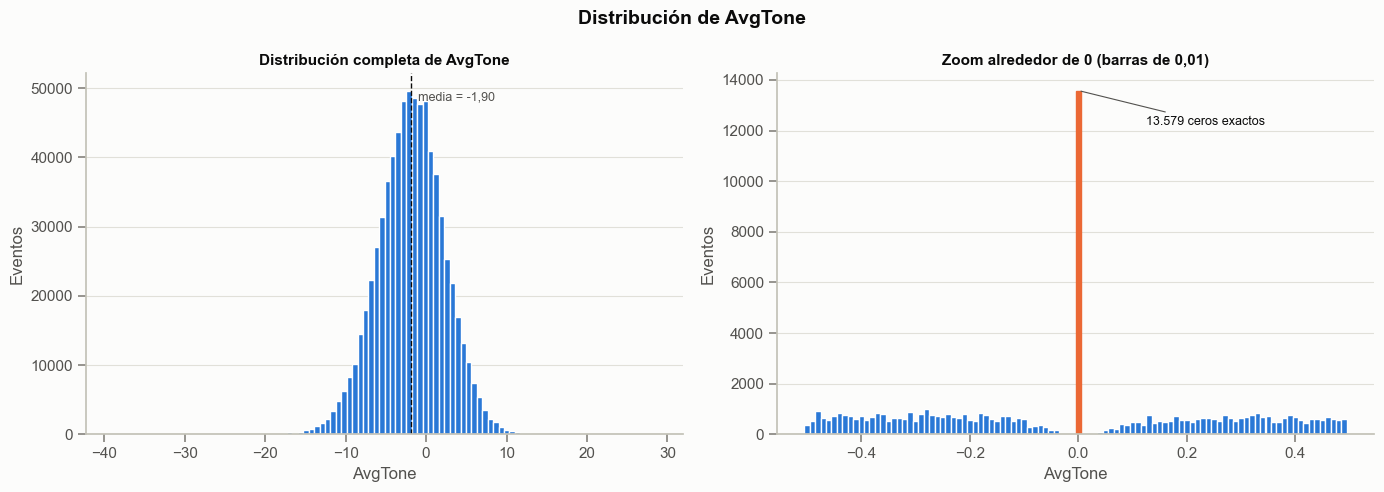

In [10]:
fig = plots.plot_zero_spike(obt["AvgTone"], "AvgTone")
plots.save_figure(fig, "avgtone_distribucion")

La distribución completa de `AvgTone` es aproximadamente simétrica, con media −1,90 y desvío 4,145 (Tabla 2). Pero en el zoom alrededor de 0 aparece un pico de 13.579 ceros exactos, mientras que los valores vecinos casi no aparecen: una variable continua que pasa de manera natural por 0 tendría también valores como 0,003 o −0,007.

In [11]:
columnas_modificadas = GEO_TYPE_COLUMNS + ZERO_AS_MISSING
obt_limpia = zeros_to_null(obt, columnas_modificadas)

null_counts(obt, obt_limpia, columnas_modificadas).style.format(
    {"nulos antes": "{:,}", "nulos después": "{:,}", "nulos agregados": "{:,}", "% nulos después": "{:.2f}"}
).set_caption("Tabla 3. Nulos antes y después de reemplazar los ceros")

,nulos antes,nulos después,nulos agregados,% nulos después
columna,,,,
Actor1Geo_Type,0,"87,091","87,091",11.80
Actor2Geo_Type,0,"228,304","228,304",30.94
ActionGeo_Type,0,"19,052","19,052",2.58
AvgTone,0,"13,579","13,579",1.84


### 2.2 Selección de variables

> **Prompt 4.** *Separá las columnas de la tabla en numéricas, categóricas y excluidas.*
> *Seguí los siguientes criterios:*
>
> - *Excluí lo que no describe al evento: identificadores (dejá GLOBALEVENTID como índice), fechas, URLs y texto libre; también las columnas redundantes (descripciones de códigos, variables que se deducen de otra o muy correlacionadas) y las que tienen casi todos sus valores nulos.*
> - *Para las categóricas jerárquicas, quedate con el nivel más general; a los nulos tratalos como una categoría explícita.*
> - *Agregá como numérica la antigüedad de la noticia en días.*
>
> *Por úlrimo, Descartá los eventos con AvgTone nulo y mostrá la cardinalidad de cada categórica, sin aplicar todavía la reducción de cardinalidad.*

#### 2.2.1 Rol de cada columna

In [12]:
from src.features import (
    AGE_COLUMN,
    CATEGORICAL,
    NUMERIC,
    build_analysis_table,
    cardinality,
    column_roles,
)

roles = column_roles(list(obt_limpia.columns))
roles.groupby(["rol", "motivo"]).size().rename("columnas").to_frame().style.set_caption(
    "Tabla 4. Cantidad de columnas por rol y motivo"
)

In [13]:
roles.style.set_caption("Tabla 5. Rol de cada columna de la OBT")

,rol,motivo
columna,,
GLOBALEVENTID,excluida,Identificador (se usa como índice)
FechaEvento,excluida,Fecha (la antigüedad la resume)
SQLDATE,excluida,Fecha (la antigüedad la resume)
MonthYear,excluida,Fecha (la antigüedad la resume)
Year,excluida,Fecha (la antigüedad la resume)
FractionDate,excluida,Fecha (la antigüedad la resume)
Actor1Code,excluida,Código compuesto de actor (redundante con país y tipo)
Actor1Name,excluida,Texto libre
Actor1CountryCode,excluida,Redundante con el país de la acción


Verificación de las redundancias usadas como criterio:

In [14]:
menciones_articulos = obt_limpia[["NumMentions", "NumArticles"]].astype(float).corr().iloc[0, 1]
quad_por_raiz = obt_limpia.groupby("EventRootCode")["QuadClass"].nunique().max()
print(f"Correlación NumMentions ~ NumArticles: {menciones_articulos:.3f}")
print(f"Máxima cantidad de QuadClass distintas por EventRootCode: {quad_por_raiz}")

Correlación NumMentions ~ NumArticles: 0.965
Máxima cantidad de QuadClass distintas por EventRootCode: 1


#### 2.2.2 Tabla de análisis

`build_analysis_table` arma la tabla con las variables seleccionadas, indexada por `GLOBALEVENTID`, y descarta los eventos nulos.

In [15]:
eventos_analisis = build_analysis_table(obt_limpia)

print(f"Eventos con AvgTone nulo: {obt_limpia['AvgTone'].isna().sum():,}")
print(f"Eventos con GoldsteinScale nulo: {obt_limpia['GoldsteinScale'].isna().sum():,} "
      f"(códigos CAMEO: {sorted(obt_limpia.loc[obt_limpia['GoldsteinScale'].isna(), 'EventCode'].unique())})")
sin_goldstein = obt_limpia["GoldsteinScale"].isna()
print(f"Descripción de esos códigos en la tabla CAMEO de GDELT: "
      f"{obt_limpia.loc[sin_goldstein, 'EventCode_Desc'].unique().tolist()}")
print(f"Eventos del análisis: {len(eventos_analisis):,} de {len(obt_limpia):,}")
print(f"Variables: {len(NUMERIC)} numéricas + {len(CATEGORICAL)} categóricas | nulos restantes: "
      f"{eventos_analisis.isna().sum().sum()}")
eventos_analisis.head()

Eventos con AvgTone nulo: 13,579
Eventos con GoldsteinScale nulo: 5 (códigos CAMEO: ['1213'])
Descripción de esos códigos en la tabla CAMEO de GDELT: [<NA>]
Eventos del análisis: 724,238 de 737,822


Variables: 6 numéricas + 5 categóricas | nulos restantes: 0


,GoldsteinScale,AvgTone,NumMentions,NumSources,IsRootEvent,AntiguedadDias,EventRootCode,Actor1Type1Code,Actor2Type1Code,ActionGeo_CountryCode,ActionGeo_Type
GLOBALEVENTID,,,,,,,,,,,
1328315349,-10.0,-8.252427,2,1,1,365,19,SIN_ACTOR,SIN_TIPO,UK,4
1328315350,-5.0,-4.615385,10,1,0,365,17,SIN_ACTOR,LAB,KS,4
1328315351,3.4,3.012634,4,1,0,365,05,BUS,SIN_ACTOR,CH,4
1328315352,-7.0,-2.345936,13,2,0,365,13,GOV,SIN_ACTOR,IR,1
1328315353,-7.2,-2.25641,2,1,0,365,15,GOV,SIN_ACTOR,RS,4


#### 2.2.3 Cardinalidad de las categóricas

Calculada sobre todos los eventos del análisis, con las categorías de nulos (`SIN_ACTOR`, `SIN_TIPO`, `SIN_GEO`) incluidas.

In [16]:
cardinality(eventos_analisis).style.format(
    {"% en categorías < 5%": "{:.1f}", "% más frecuente": "{:.1f}"}
).set_caption("Tabla 7. Cardinalidad de las variables categóricas")

,categorías,categorías >= 5%,% en categorías < 5%,categoría más frecuente,% más frecuente
columna,,,,,
EventRootCode,20,7,25.5,04,25.2
Actor1Type1Code,34,3,29.5,SIN_TIPO,47.6
Actor2Type1Code,34,3,23.6,SIN_TIPO,37.6
ActionGeo_CountryCode,243,2,64.2,US,30.3
ActionGeo_Type,6,4,5.3,4,45.0


### 2.3 Reducción de cardinalidad

> **Prompt 5.** *Ok, ahora para cada categórica, agrupá en 'OTHER' las categorías con frecuencia < 5% de las filas. Después mostrame la cardinalidad antes y después y qué % de filas quedó en 'OTHER' en cada columna.*

*La frecuencia se calcula sobre todos los eventos del análisis, con las categorías de nulos incluidas.*

In [17]:
from src.features import reduce_cardinality

eventos_reducidos, resumen_cardinalidad = reduce_cardinality(eventos_analisis)
resumen_cardinalidad.style.format({"% filas en OTHER": "{:.1f}"}).set_caption(
    "Tabla 8. Cardinalidad antes y después de agrupar en OTHER las categorías con menos del 5% de las filas"
)

,categorías antes,categorías después,% filas en OTHER,categorías conservadas
columna,,,,
EventRootCode,20,8,25.5,"04, 01, 05, 02, 11, 03, 19"
Actor1Type1Code,34,4,29.5,"SIN_TIPO, GOV, SIN_ACTOR"
Actor2Type1Code,34,4,23.6,"SIN_TIPO, SIN_ACTOR, GOV"
ActionGeo_CountryCode,243,3,64.2,"US, IN"
ActionGeo_Type,6,5,5.3,"4, 1, 3, 2"


### 2.4 Variables indicadoras

> **Prompt 6.** *Ok, ahora codificá las variables categóricas como variables indicadoras (0 o 1), con k − 1 indicadoras por variable:*
> - *Omití la categoría OTHER como categoría de referencia (la que no tiene su propia indicadora).*
> - *Nombrá cada indicadora como variable_categoría. Y después armá la matriz de datos combinando las numéricas con las indicadoras, indexá por GLOBALEVENTID, y mostrá cuántas indicadoras quedaron por variable y la dimensión final de la matriz.*

*La matriz se guarda también en `data/processed/matriz_datos.parquet`.*

In [18]:
from src.config import MATRIX_PARQUET
from src.features import build_matrix, encode_dummies

indicadoras, resumen_indicadoras = encode_dummies(eventos_reducidos)
resumen_indicadoras.style.set_caption("Tabla 9. Indicadoras generadas por variable categórica")

,categorías,indicadoras,categoría de referencia
variable,,,
EventRootCode,8,7,OTHER
Actor1Type1Code,4,3,OTHER
Actor2Type1Code,4,3,OTHER
ActionGeo_CountryCode,3,2,OTHER
ActionGeo_Type,5,4,OTHER


In [19]:
matriz = build_matrix(eventos_reducidos, indicadoras)
matriz.to_parquet(MATRIX_PARQUET)

print(f"Matriz de datos: {matriz.shape[0]:,} eventos x {matriz.shape[1]} variables "
      f"({len(NUMERIC)} numéricas + {indicadoras.shape[1]} indicadoras)")
print("Indicadoras:", ", ".join(indicadoras.columns))
matriz.head()

Matriz de datos: 724,238 eventos x 25 variables (6 numéricas + 19 indicadoras)
Indicadoras: EventRootCode_01, EventRootCode_02, EventRootCode_03, EventRootCode_04, EventRootCode_05, EventRootCode_11, EventRootCode_19, Actor1Type1Code_GOV, Actor1Type1Code_SIN_ACTOR, Actor1Type1Code_SIN_TIPO, Actor2Type1Code_GOV, Actor2Type1Code_SIN_ACTOR, Actor2Type1Code_SIN_TIPO, ActionGeo_CountryCode_IN, ActionGeo_CountryCode_US, ActionGeo_Type_1, ActionGeo_Type_2, ActionGeo_Type_3, ActionGeo_Type_4


,GoldsteinScale,AvgTone,NumMentions,NumSources,IsRootEvent,AntiguedadDias,EventRootCode_01,EventRootCode_02,EventRootCode_03,EventRootCode_04,EventRootCode_05,EventRootCode_11,EventRootCode_19,Actor1Type1Code_GOV,Actor1Type1Code_SIN_ACTOR,Actor1Type1Code_SIN_TIPO,Actor2Type1Code_GOV,Actor2Type1Code_SIN_ACTOR,Actor2Type1Code_SIN_TIPO,ActionGeo_CountryCode_IN,ActionGeo_CountryCode_US,ActionGeo_Type_1,ActionGeo_Type_2,ActionGeo_Type_3,ActionGeo_Type_4
GLOBALEVENTID,,,,,,,,,,,,,,,,,,,,,,,,,
1328315349,-10.0,-8.252427,2.0,1.0,1.0,365.0,0,0,0,0,0,0,1,0,1,0,0,0,1,0,0,0,0,0,1
1328315350,-5.0,-4.615385,10.0,1.0,0.0,365.0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1
1328315351,3.4,3.012634,4.0,1.0,0.0,365.0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,1
1328315352,-7.0,-2.345936,13.0,2.0,0.0,365.0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0,0,0
1328315353,-7.2,-2.256410,2.0,1.0,0.0,365.0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,1


### 2.5 Reducción de la dimensionalidad (ACP)

> **Prompt 7.** *Ahora, antes de pasar al análisis de componentes principales, quiero que me muestres los gráficos de las distribuciónes de cada variable numérica.*

*Cada variable se grafica según su forma: histograma para las continuas, barras para las discretas, y eje *y* logarítmico para las muy asimétricas, para que se vea su cola.*

In [20]:
numericas = matriz[NUMERIC]
estadisticos = numericas.describe().T[["mean", "std", "min", "50%", "max"]]
estadisticos["asimetría"] = numericas.skew()
estadisticos["valor más frecuente"] = [numericas[c].value_counts().index[0] for c in NUMERIC]
estadisticos["% valor más frecuente"] = [numericas[c].value_counts(normalize=True).iloc[0] * 100 for c in NUMERIC]
# Desvíos estándar a los que queda el valor más extremo al estandarizar.
estadisticos["z máximo"] = ((numericas - numericas.mean()) / numericas.std()).abs().max()
estadisticos.style.format("{:.2f}").set_caption("Tabla 10. Estadísticos de las variables numéricas")

,mean,std,min,50%,max,asimetría,valor más frecuente,% valor más frecuente,z máximo
GoldsteinScale,0.58,4.56,-10.00,1.00,10.00,-0.67,0.00,10.88,2.32
AvgTone,-1.94,4.18,-38.89,-1.93,28.57,-0.11,-5.00,0.08,8.85
NumMentions,4.63,4.25,1.00,4.00,240.00,7.15,2.00,26.53,55.37
NumSources,1.05,0.42,1.00,1.00,20.00,16.51,1.00,97.24,44.82
IsRootEvent,0.52,0.50,0.00,1.00,1.00,-0.08,1.00,52.06,1.04
AntiguedadDias,2.80,55.20,0.00,0.00,3650.00,52.09,0.00,98.06,66.07


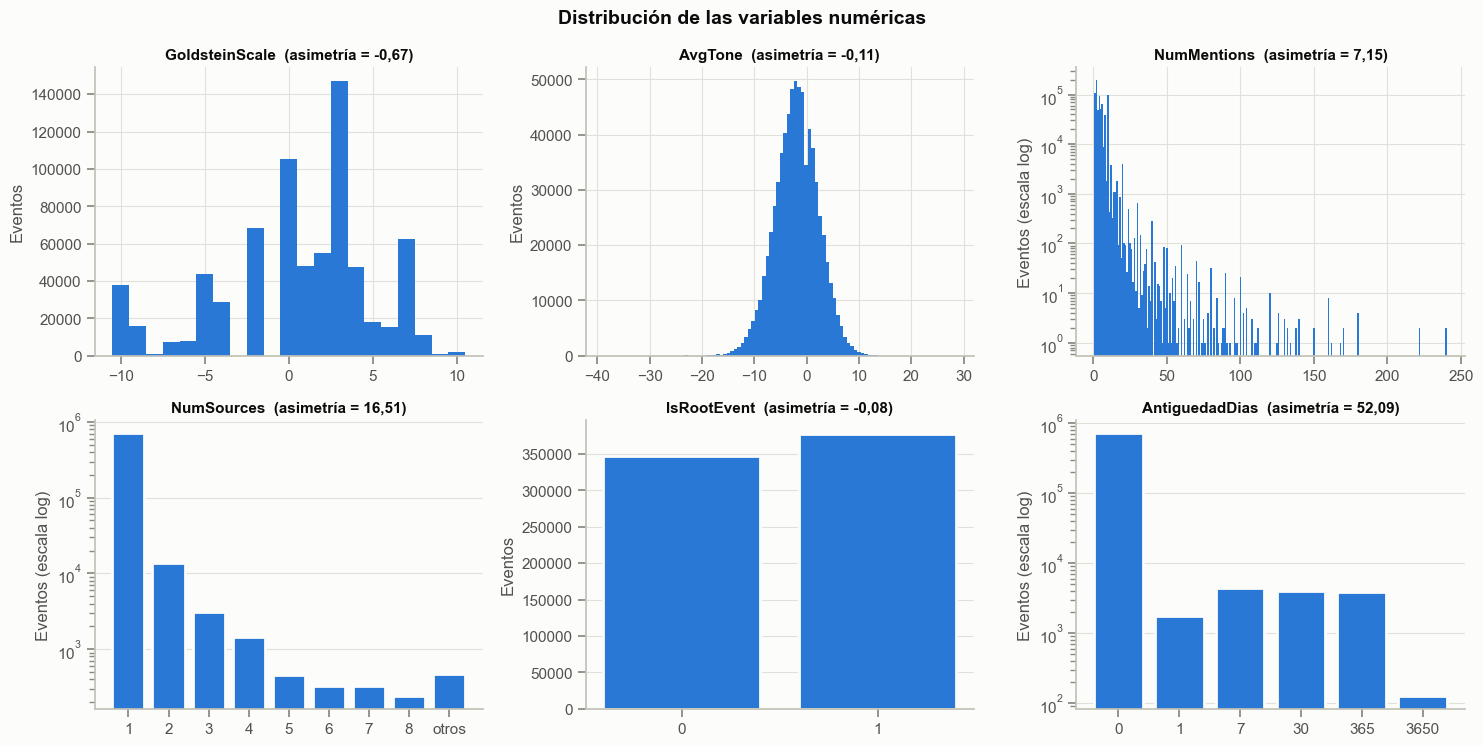

In [21]:
fig = plots.plot_numeric_distributions(numericas, {
    "GoldsteinScale": "hist",
    "AvgTone": "hist",
    "NumMentions": "hist_log",
    "NumSources": "bar_log",
    "IsRootEvent": "bar",
    AGE_COLUMN: "bar_log",
})
plots.save_figure(fig, "distribuciones_numericas")

**Observaciones:**

- **`GoldsteinScale`** es discreta y multimodal: cada código CAMEO tiene un valor fijo (verificado en 2.1). El más frecuente es 0 (Tabla 10).
- **`AvgTone`** es casi simétrica, centrada en −1,94.
- **`IsRootEvent`** está balanceada: el 52% de los eventos está en el párrafo principal de la nota.
- **`NumMentions`, `NumSources` y `AntiguedadDias`** son muy asimétricas: casi todos los eventos están en el mínimo (el 97% tiene 1 fuente y el 98%, antigüedad 0), con una cola larga. Al estandarizarlas, sus extremos quedan a entre 45 y 66 desvíos de la media (columna "z máximo" de la Tabla 10), así que van a pesar mucho en la detección de atípicos. En el ACP, en cambio, todas pesan lo mismo de entrada: al estandarizar, cada variable aporta varianza 1.


> **Prompt 8.** *Escalá las variables de la matriz de datos con z-score (media 0, desvío 1), incluidas las indicadoras, y aplicá ACP. Las variables asimétricas (NumMentions, NumSources y AntiguedadDias) entran sin transformar, para no perder los valores extremos que buscamos como eventos raros.*
>
> *Después graficá, uno al lado del otro, el scree plot (autovalor de cada componente, con la línea de Kaiser en 1) y la varianza explicada acumulada (con líneas en 80% y 90%). Mostrá una tabla con cuántas componentes da cada criterio: Kaiser, codo, 80% y 90% de varianza.*

**Criterio del codo:** para que no dependa de mirar el gráfico, se toma como codo el punto de la curva de autovalores más alejado de la recta que une el primer autovalor con el último. Hasta ahí la curva cae rápido; a partir de ahí se aplana.

In [22]:
from src.pca import elbow, retention_criteria, run_pca

acp = run_pca(matriz)
print(f"ACP sobre {matriz.shape[0]:,} eventos x {matriz.shape[1]} variables estandarizadas")
acp.variance_table().style.format({"autovalor": "{:.3f}", "% varianza": "{:.2f}", "% varianza acumulada": "{:.2f}"}).set_caption("Tabla 11. Autovalores y varianza explicada")

ACP sobre 724,238 eventos x 25 variables estandarizadas


,autovalor,% varianza,% varianza acumulada
componente,,,
PC1,2.396,9.58,9.58
PC2,2.045,8.18,17.76
PC3,1.739,6.96,24.72
PC4,1.552,6.21,30.93
PC5,1.437,5.75,36.68
PC6,1.333,5.33,42.01
PC7,1.198,4.79,46.80
PC8,1.186,4.74,51.55
PC9,1.146,4.58,56.13


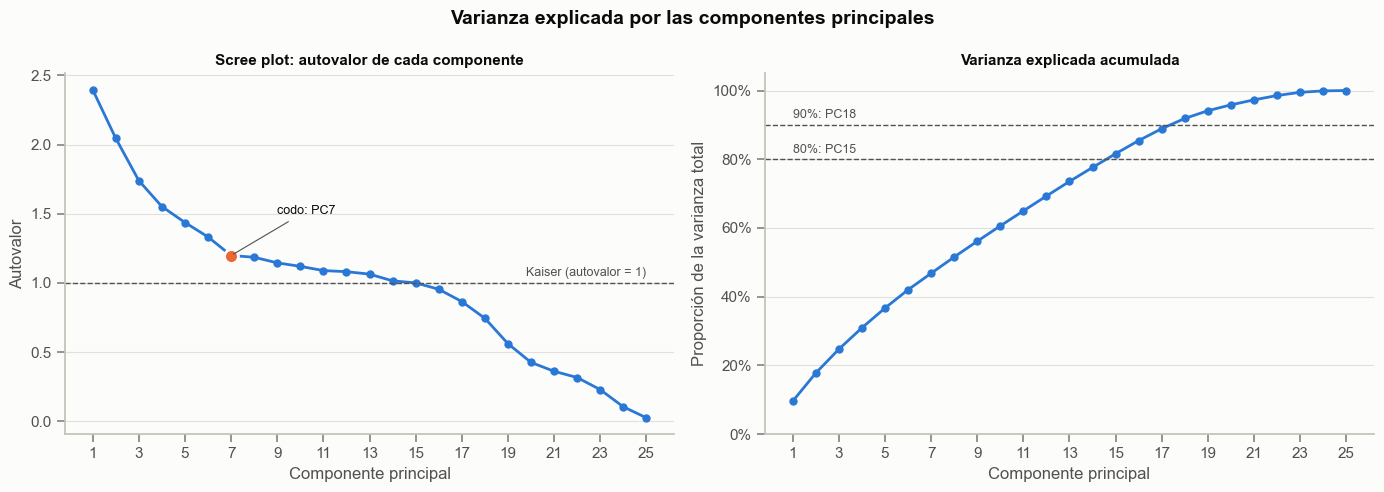

In [23]:
fig = plots.plot_scree(acp.eigenvalues, acp.var_exp, elbow(acp.eigenvalues))
plots.save_figure(fig, "scree_plot")

In [24]:
retention_criteria(acp).style.format({"% varianza explicada": "{:.1f}"}).set_caption(
    "Tabla 12. Componentes retenidas por cada criterio"
)

,componentes,% varianza explicada
criterio,,
Kaiser (autovalor > 1),15,81.6
Codo del scree plot,7,46.8
80% de varianza acumulada,15,81.6
90% de varianza acumulada,18,91.9


**Observaciones:**

- **El espectro es plano:** la primera componente explica sólo el 9,6% de la varianza, y desde PC7 hasta PC15 los autovalores se mantienen casi constantes, entre 1,20 y 1,00. Las variables comparten poca información entre sí.
- **Kaiser y el 80% coinciden en 15 componentes** (81,6% de la varianza). Pero el criterio de Kaiser queda en el límite: PC15 tiene autovalor 1,001, apenas por encima de 1.
- **El codo está en PC7** (46,8% de la varianza): es donde termina la caída rápida de los autovalores y empieza la meseta.
- **El 90% pide 18 componentes** (91,9%), de 25 variables.
- **Las últimas componentes tienen autovalores chicos pero no nulos** (PC25: 0,027): con *k − 1* indicadoras no aparecen componentes con autovalor 0.

### 2.6 Detección de eventos atípicos

> **Prompt 9.** *Quedate con 15 componentes (por criterios de Kaiser y el 80% de varianza acumulada).*
> *Sobre las coordenadas de los eventos en esas componentes, aplicá dos métodos de detección de atípicos multivariantes:*
>
> 1. *Distancia euclídea de cada evento al centro, con Tukey fences (Q3 + 2·IQR) como umbral.*
> 2. *Isolation Forest, con una contaminación del 1%.*
>
> *Luego mostrá cuántos eventos marca cada método y cuántos marcan los dos.*

Los métodos utilizados son: la **distancia al centro** mide qué tan lejos está un evento del perfil típico, e **Isolation Forest**, que mide qué tan fácil es aislarlo con cortes al azar. Para el umbral de la distancia se usan las Tukey fences, que no suponen normalidad; un umbral de z-score (z > 3) sí la supondría, y la distribución de las distancias no es normal: su asimetría es de 15 y la prueba de Anderson-Darling rechaza la normalidad (ver la salida de la primera celda de abajo).

In [25]:
from src.outliers import center_distance, isolation_forest, overlap_table, tukey_upper_fence

N_COMPONENTES = 15
coordenadas = acp.scores.iloc[:, :N_COMPONENTES]
print(f"Componentes: {N_COMPONENTES} ({acp.cum_var_exp[N_COMPONENTES - 1]:.1%} de la varianza)")

distancia = center_distance(coordenadas)
umbral_tukey = tukey_upper_fence(distancia, k=2)
atipico_distancia = (distancia > umbral_tukey).astype(int).rename("atipico_distancia")
print(f"Distancia al centro: Q3 + 2·IQR = {umbral_tukey:.2f}")

# ¿Son normales las distancias? Asimetría y prueba de Anderson-Darling.
from scipy.stats import anderson

prueba = anderson(distancia, dist="norm")
print(f"Asimetría de las distancias: {distancia.skew():.2f}")
print(f"Anderson-Darling: estadístico = {prueba.statistic:.1f}, valor crítico al 1% = {prueba.critical_values[-1]:.3f} "
      f"-> {'se rechaza' if prueba.statistic > prueba.critical_values[-1] else 'no se rechaza'} la normalidad")

Componentes: 15 (81.6% de la varianza)
Distancia al centro: Q3 + 2·IQR = 7.82


Asimetría de las distancias: 15.06
Anderson-Darling: estadístico = 21461.5, valor crítico al 1% = 1.092 -> se rechaza la normalidad


In [26]:
atipico_iforest, puntaje_iforest = isolation_forest(coordenadas, contamination=0.01)

deteccion = pd.concat([distancia, atipico_distancia, puntaje_iforest, atipico_iforest], axis=1)
deteccion["atipico_ambos"] = (deteccion["atipico_distancia"] & deteccion["atipico_iforest"]).astype(int)

pd.DataFrame({
    "eventos marcados": deteccion[["atipico_distancia", "atipico_iforest", "atipico_ambos"]].sum(),
    "% de los eventos": deteccion[["atipico_distancia", "atipico_iforest", "atipico_ambos"]].mean() * 100,
}, index=["atipico_distancia", "atipico_iforest", "atipico_ambos"]).rename(index={
    "atipico_distancia": "Distancia al centro (Tukey)",
    "atipico_iforest": "Isolation Forest (1%)",
    "atipico_ambos": "Ambos métodos",
}).style.format({"eventos marcados": "{:,}", "% de los eventos": "{:.2f}"}).set_caption(
    "Tabla 13. Eventos atípicos marcados por cada método"
)

,eventos marcados,% de los eventos
Distancia al centro (Tukey),"4,960",0.68
Isolation Forest (1%),"7,242",1.00
Ambos métodos,"4,012",0.55


In [27]:
overlap_table(deteccion["atipico_distancia"], deteccion["atipico_iforest"],
              "Distancia al centro (Tukey)", "Isolation Forest").style.format("{:,}").set_caption(
    "Tabla 14. Coincidencia entre los dos métodos"
)

Isolation Forest,atípico,normal,total
Distancia al centro (Tukey),,,
atípico,"4,012",948,"4,960"
normal,"3,230","716,048","719,278"
total,"7,242","716,996","724,238"


In [28]:
correlacion = deteccion[["distancia_centro", "puntaje_iforest"]].corr(method="spearman").iloc[0, 1]
print(f"Correlación de Spearman entre los puntajes de los dos métodos: {correlacion:.3f}")

Correlación de Spearman entre los puntajes de los dos métodos: 0.952


**Observaciones:**

- **La distancia al centro marca 4.960 eventos** (0,68%) por encima de Q3 + 2·IQR = 7,82, e **Isolation Forest, 7.242** (1%, la contaminación elegida).
- **Los dos métodos coinciden mucho:** 4.012 eventos los marcan ambos, el 81% de los que marca la distancia. Sus puntajes ordenan a los eventos de forma muy parecida (Spearman 0,95).
- **Las diferencias son de borde:** 948 eventos los marca sólo la distancia y 3.230 sólo Isolation Forest, que marca más porque su umbral (1%) es más amplio que el de Tukey (0,68%).

> **Prompt 10.** *Criterio: Quedate como atípicos finales con los eventos que marcan los dos métodos simultaneamente.*
> 1. *Quedate como atípicos finales con los eventos que marcan los dos métodos simultaneamente.*
> 2. *Ordenalos por la distancia al centro, de mayor a menor.*
> 3. *Mostrá cuántos atípicos quedan y una tabla que compare su perfil medio con el de los eventos "normales" (Goldstein, tono, menciones, fuentes y antigüedad).*

Se toman como **eventos normales** los que no marca ningún método. Los que marca uno solo quedan afuera de la comparación: no son atípicos finales, pero tampoco son normales para ninguno de los dos criterios.

In [29]:
atipicos = deteccion[deteccion["atipico_ambos"] == 1].sort_values("distancia_centro", ascending=False)
normales = deteccion[(deteccion["atipico_distancia"] == 0) & (deteccion["atipico_iforest"] == 0)]
un_solo_metodo = len(deteccion) - len(atipicos) - len(normales)

print(f"Atípicos finales (marcados por los dos métodos): {len(atipicos):,} ({len(atipicos) / len(deteccion):.2%})")
print(f"Eventos normales (no los marca ningún método): {len(normales):,}")
print(f"Descartados por marcarlos un solo método: {un_solo_metodo:,}")
atipicos.head(10)

Atípicos finales (marcados por los dos métodos): 4,012 (0.55%)
Eventos normales (no los marca ningún método): 716,048
Descartados por marcarlos un solo método: 4,178


,distancia_centro,atipico_distancia,puntaje_iforest,atipico_iforest,atipico_ambos
GLOBALEVENTID,,,,,
1328419537,65.767787,1,0.602802,1,1
1328419535,65.743349,1,0.650189,1,1
1328419536,65.743349,1,0.650189,1,1
1329022656,65.724640,1,0.663626,1,1
1328518935,65.723856,1,0.631645,1,1
1328847006,65.723186,1,0.663626,1,1
1328847005,65.706246,1,0.658683,1,1
1329022655,65.703257,1,0.658237,1,1
1328818384,65.693126,1,0.594368,1,1


In [30]:
variables_perfil = ["GoldsteinScale", "AvgTone", "NumMentions", "NumSources", AGE_COLUMN]
perfil = pd.DataFrame({
    "atípicos": matriz.loc[atipicos.index, variables_perfil].mean(),
    "normales": matriz.loc[normales.index, variables_perfil].mean(),
})
perfil["atípicos / normales"] = perfil["atípicos"] / perfil["normales"]
for grupo, ids in (("atípicos", atipicos.index), ("normales", normales.index)):
    antiguedad = matriz.loc[ids, AGE_COLUMN]
    print(f"{grupo}: {(antiguedad > 0).mean():.1%} con antigüedad > 0 | máximo: {antiguedad.max():.0f} días")
perfil.style.format("{:.2f}").set_caption("Tabla 15. Perfil medio de los atípicos frente a los eventos normales")

atípicos: 28.1% con antigüedad > 0 | máximo: 3650 días
normales: 1.7% con antigüedad > 0 | máximo: 365 días


,atípicos,normales,atípicos / normales
GoldsteinScale,0.16,0.60,0.27
AvgTone,-2.43,-1.93,1.26
NumMentions,24.44,4.51,5.42
NumSources,4.63,1.03,4.51
AntiguedadDias,201.88,1.31,153.82


**Observaciones:**

- **Los atípicos son eventos de cobertura excepcional:** tienen en promedio 24,4 menciones y 4,6 fuentes, contra 4,5 y 1,0 de los normales (5,4 y 4,5 veces más).
- **Reaparecen más noticias viejas:** su antigüedad media es de 202 días, contra 1,3 de los normales. La media está empujada por pocos eventos: sólo el 28,1% de los atípicos tiene antigüedad mayor a 0, con un máximo de 3650 días (10 años), contra el 1,7% de los normales.
- **Son algo más conflictivos y negativos:** Goldstein medio de 0,16 contra 0,60, y tono de −2,43 contra −1,93.

> **Prompt 11.** *Mostrá qué tipos de evento (raíz CAMEO, con su descripción) predominan entre los atípicos frente a los normales.*
> *Después mostrá los 10 atípicos con mayor distancia al centro, unidos a la OBT para que se puedan leer: fecha, actores, descripción del vento, país, tono, Goldstein, menciones, fuentes, antigüedad y URL.*

*Los tipos de evento se toman de la OBT, que conserva las 20 raíces CAMEO (en la matriz de datos, las poco frecuentes quedaron agrupadas en `OTHER`). La tabla se ordena por la diferencia entre los dos grupos, en puntos porcentuales: arriba quedan los tipos que más se sobrerrepresentan entre los atípicos.*

In [31]:
obt_eventos = obt_limpia.set_index("GLOBALEVENTID")
raiz = obt_eventos["EventRootCode"] + " " + obt_eventos["EventRootCode_Desc"].str.title()

tipos = pd.DataFrame({
    "% atípicos": raiz.loc[atipicos.index].value_counts(normalize=True) * 100,
    "% normales": raiz.loc[normales.index].value_counts(normalize=True) * 100,
}).fillna(0)
tipos["diferencia (pp)"] = tipos["% atípicos"] - tipos["% normales"]
tipos.index.name = "raíz CAMEO"
tipos.sort_values("diferencia (pp)", ascending=False).style.format("{:.2f}").background_gradient(
    subset=["diferencia (pp)"], cmap="RdBu_r", vmin=-10, vmax=10
).set_caption("Tabla 16. Tipos de evento entre los atípicos y los eventos normales")

,% atípicos,% normales,diferencia (pp)
raíz CAMEO,,,
03 Express Intent To Cooperate,13.04,5.89,7.15
19 Fight,11.79,5.34,6.45
11 Disapprove,7.40,6.64,0.76
02 Appeal,7.40,7.32,0.08
20 Use Unconventional Mass Violence,0.02,0.03,-0.01
18 Assault,1.42,1.52,-0.09
08 Yield,3.19,3.30,-0.11
15 Exhibit Force Posture,0.22,0.36,-0.13
16 Reduce Relations,0.47,0.75,-0.28


La diferencia es el % entre los atípicos menos el % entre los normales, en puntos porcentuales (pp). Si es **positiva** (rojo), ese tipo de evento es más frecuente entre los atípicos: está sobrerrepresentado. Si es **negativa** (azul), es menos frecuente: está subrepresentado. Cerca de 0, aparece en la misma proporción en los dos grupos. Como en cada grupo los porcentajes suman 100%, las diferencias suman 0: lo que unos tipos ganan entre los atípicos, otros lo pierden.

Los atípicos se distinguen por dos tipos de evento opuestos, que aparecen en más del doble de proporción que entre los normales: la **expresión de intención de cooperar** (`03`: 13,0% contra 5,9%) y el **combate** (`19`: 11,8% contra 5,3%). El resto de las raíces tiene diferencias de menos de 2 pp, salvo las **consultas** (`04`), el tipo de evento más común, que entre los atípicos aparece menos (21,1% contra 25,3%).

In [32]:
columnas_lectura = {
    "FechaEvento": "fecha",
    "Actor1Name": "actor 1",
    "Actor2Name": "actor 2",
    "EventCode_Desc": "evento",
    "ActionGeo_CountryCode_Desc": "país",
    "AvgTone": "tono",
    "GoldsteinScale": "Goldstein",
    "NumMentions": "menciones",
    "NumSources": "fuentes",
    "SOURCEURL": "URL",
}
top_atipicos = obt_eventos.loc[atipicos.index[:10], list(columnas_lectura)].rename(columns=columnas_lectura)
top_atipicos.insert(len(top_atipicos.columns) - 1, "antigüedad (días)", eventos_analisis.loc[top_atipicos.index, AGE_COLUMN])
top_atipicos.insert(0, "distancia", atipicos["distancia_centro"].iloc[:10])

with pd.option_context("display.max_colwidth", None):
    display(top_atipicos.style.format({"distancia": "{:.1f}", "tono": "{:.2f}", "Goldstein": "{:.1f}",
                                        "fecha": "{:%Y-%m-%d}"}, na_rep="—")
            .set_caption("Tabla 17. Los 10 atípicos con mayor distancia al centro"))

,distancia,fecha,actor 1,actor 2,evento,país,tono,Goldstein,menciones,fuentes,antigüedad (días),URL
GLOBALEVENTID,,,,,,,,,,,,
1328419537,65.8,2016-10-19,MIAMI,—,"Use conventional military force, not specified below",United States,-3.32,-10.0,6,1,3650,https://www.governing.com/archive/gov-miami-mental-health-jail.html
1328419535,65.7,2016-10-19,MIAMI,—,"Use conventional military force, not specified below",United States,-3.32,-10.0,2,1,3650,https://www.governing.com/archive/gov-miami-mental-health-jail.html
1328419536,65.7,2016-10-19,MIAMI,—,"Use conventional military force, not specified below",United States,-3.32,-10.0,2,1,3650,https://www.governing.com/archive/gov-miami-mental-health-jail.html
1329022656,65.7,2016-10-23,—,BRITISH,"Use conventional military force, not specified below",United Kingdom,-6.70,-10.0,6,1,3650,https://www.theguardian.com/commentisfree/2026/oct/21/australian-history-of-political-violence-helen-haines-ntwnfb
1328518935,65.7,2016-10-20,DANISH,GOVERNANCE,Praise or endorse,Denmark,-0.79,3.4,3,1,3650,http://businessghana.com/site/news/general/357890/Ghana-calls-for-stronger-African-cooperation
1328847006,65.7,2016-10-22,—,BRITISH,"Use conventional military force, not specified below",United Kingdom,-6.27,-10.0,6,1,3650,https://www.miragenews.com/australias-peaceful-democracy-has-history-of-1763366/
1328847005,65.7,2016-10-22,—,UNITED KINGDOM,"Use conventional military force, not specified below",United Kingdom,-6.27,-10.0,2,1,3650,https://www.miragenews.com/australias-peaceful-democracy-has-history-of-1763366/
1329022655,65.7,2016-10-23,—,UNITED KINGDOM,"Use conventional military force, not specified below",United Kingdom,-6.70,-10.0,4,1,3650,https://www.theguardian.com/commentisfree/2026/oct/21/australian-history-of-political-violence-helen-haines-ntwnfb
1328818384,65.7,2016-10-22,MISSOURI,—,Express intent to meet or negotiate,United States,1.20,4.0,3,1,3650,https://themissouritimes.com/state-senate-tipsheet-october-2026/


In [33]:
antiguedad_atipicos = eventos_analisis.loc[atipicos.index, AGE_COLUMN]
urls_atipicos = obt_eventos.loc[atipicos.index, "SOURCEURL"]
print(f"Atípicos con antigüedad de 3650 días: {(antiguedad_atipicos == 3650).sum()} "
      f"(de {(eventos_analisis[AGE_COLUMN] == 3650).sum()} en todo el análisis)")
for n in (10, 100, 500):
    print(f"Primeros {n} por distancia: {(antiguedad_atipicos.iloc[:n] == 3650).mean():.0%} con antigüedad de 3650 días, "
          f"{urls_atipicos.iloc[:n].nunique()} URLs distintas")
print(f"URLs distintas entre los {len(atipicos):,} atípicos: {urls_atipicos.nunique():,}")

Atípicos con antigüedad de 3650 días: 127 (de 127 en todo el análisis)
Primeros 10 por distancia: 100% con antigüedad de 3650 días, 6 URLs distintas
Primeros 100 por distancia: 100% con antigüedad de 3650 días, 49 URLs distintas
Primeros 500 por distancia: 25% con antigüedad de 3650 días, 190 URLs distintas
URLs distintas entre los 4,012 atípicos: 1,439


**Observaciones:**

- **Los primeros del orden por distancia son referencias a hechos de hace diez años:** los 10 tienen antigüedad de 3650 días, y lo mismo pasa con los 100 primeros. 3650 días son exactamente 10 años: son notas de esta semana que mencionan hechos de hace una década. Por ejemplo, en la Tabla 17 aparece una nota de octubre de 2026 sobre la historia de la violencia política (su URL tiene la fecha), registrada con fecha de 2016. Como `AntiguedadDias` entra sin transformar, ese valor extremo domina la distancia al centro.
- **Muchos atípicos salen de la misma nota:** los 4.012 provienen de sólo 1.439 URLs, porque GDELT extrae varios eventos de cada artículo. Entre los 10 primeros hay sólo 6 URLs distintas.

### 2.7 Exportación de los atípicos

> **Prompt 13.**
> 1. *Exportá los atípicos finales en una tabla separada, incorporando la información descriptiva de la OBT: fecha, actores, tipo de evento, país, tono, Goldstein, menciones, fuentes, antigüedad y URL.*
> 2. *Agregá también los puntajes obtenidos con ambos métodos y una columna que indique cuántos eventos comparten la misma URL.*
> 3. *Ordená los resultados de mayor a menor según el puntaje de Isolation Forest.*
> 4. *Por último, guardá la tabla en formatos Parquet y CSV.*

In [34]:
from src.config import OUTLIERS_CSV, OUTLIERS_PARQUET
from src.outliers import outlier_table

tabla_atipicos = outlier_table(atipicos, obt_eventos, eventos_analisis[AGE_COLUMN])
tabla_atipicos.to_parquet(OUTLIERS_PARQUET, index=False)
# utf-8-sig: con BOM, para que Excel lea bien los acentos.
tabla_atipicos.to_csv(OUTLIERS_CSV, index=False, encoding="utf-8-sig")

print(f"Atípicos exportados: {len(tabla_atipicos):,} eventos x {tabla_atipicos.shape[1]} columnas")
for archivo in (OUTLIERS_PARQUET, OUTLIERS_CSV):
    print(f"  {archivo.relative_to(TP_ROOT)} ({archivo.stat().st_size / 1e6:.1f} MB)")

Atípicos exportados: 4,012 eventos x 19 columnas
  data\processed\eventos_atipicos.parquet (0.3 MB)
  data\processed\eventos_atipicos.csv (1.3 MB)


In [35]:
with pd.option_context("display.max_colwidth", 60):
    display(tabla_atipicos.head(10).style.format({
        "fecha": "{:%Y-%m-%d}", "tono": "{:.2f}", "goldstein": "{:.1f}",
        "distancia_centro": "{:.1f}", "puntaje_iforest": "{:.3f}",
    }, na_rep="—").set_caption("Tabla 18. Primeros 10 atípicos exportados (orden por Isolation Forest)"))

,GLOBALEVENTID,fecha,actor_1,tipo_actor_1,actor_2,tipo_actor_2,tipo_evento,evento,pais,lugar,tono,goldstein,menciones,fuentes,antiguedad_dias,url,distancia_centro,puntaje_iforest,atipicos_misma_url
0,1328541701,2026-10-18,WEST BANK,Civilian,ISRAEL,Civilian,FIGHT,Fight with small arms and light weapons,West Bank,West Bank,-10.27,-10.0,38,19,0,https://www.huntspost.co.uk/news/national/26646995.us-ambassador-israel-condemns-settler-attack-journalist/,37.1,0.756,4
1,1329466692,2026-10-23,MILITARY,Military,UNITED KINGDOM,—,FIGHT,"Use conventional military force, not specified below",United Kingdom,"Stourbridge, Dudley, United Kingdom",-0.15,-10.0,160,16,0,https://www.burnhamandhighbridgeweeklynews.co.uk/news/national/26663822.andy-burnham-hosts-wildfire-summit-build-resilience-for-next-time/,50.5,0.755,17
2,1329466532,2026-10-23,UNITED KINGDOM,—,MILITARY,Military,FIGHT,"Use conventional military force, not specified below",United Kingdom,"Stourbridge, Dudley, United Kingdom",-0.15,-10.0,160,16,0,https://www.burnhamandhighbridgeweeklynews.co.uk/news/national/26663822.andy-burnham-hosts-wildfire-summit-build-resilience-for-next-time/,50.5,0.755,17
3,1328948765,2025-10-20,LONDON,—,UNITED KINGDOM,Education,CONSULT,Host a visit,United Kingdom,"London, London, City of, United Kingdom",4.78,2.8,134,16,365,https://www.braintreeandwithamtimes.co.uk/news/national/26655264.fka-twigs-curate-headline-southbank-centres-meltdown-festival/,46.9,0.752,6
4,1328452087,2026-10-17,INTERIOR MINIST,Government,PARIS,—,PROTEST,"Engage in political dissent, not specified below",France,"Paris, France (general), France",-7.13,-6.5,140,14,0,https://www.newsandstar.co.uk/news/national/26646131.tear-gas-used-paris-protesters-rally-across-france/,43.9,0.752,10
5,1328948764,2025-10-20,LONDON,—,COLLEGE,Education,CONSULT,Host a visit,United Kingdom,"London, London, City of, United Kingdom",4.80,2.8,34,16,365,https://www.braintreeandwithamtimes.co.uk/news/national/26655264.fka-twigs-curate-headline-southbank-centres-meltdown-festival/,31.9,0.752,6
6,1328462900,2026-10-17,PHYSICIAN,Health,OPERATIVE,State Intelligence,MAKE PUBLIC STATEMENT,"Make statement, not specified below",Italy,"Rome, Lazio, Italy",-1.65,0.0,160,16,0,https://www.thisiswiltshire.co.uk/news/national/26646208.pope-leo-returns-vatican-four-days-lung-cancer-surgery/,50.5,0.751,2
7,1329466547,2026-10-23,PRIME MINISTER,Government,—,—,APPEAL,"Appeal, not specified below",United Kingdom,"Stourbridge, Dudley, United Kingdom",-0.15,3.0,160,16,0,https://www.burnhamandhighbridgeweeklynews.co.uk/news/national/26663822.andy-burnham-hosts-wildfire-summit-build-resilience-for-next-time/,50.7,0.751,17
8,1329509759,2026-10-23,UNITED KINGDOM,—,KING,Government,REJECT,"Reject proposal to meet, discuss, or negotiate",United Kingdom,"Nottingham, Nottingham, United Kingdom",-3.07,-5.0,60,15,0,https://www.keighleynews.co.uk/news/national/26665564.meghan-informed-disturbing-allegations-father-2018/,33.4,0.751,1
9,1328948767,2025-10-20,UNITED KINGDOM,Education,LONDON,—,CONSULT,Make a visit,United Kingdom,"London, London, City of, United Kingdom",4.75,1.9,33,16,365,https://www.braintreeandwithamtimes.co.uk/news/national/26655264.fka-twigs-curate-headline-southbank-centres-meltdown-festival/,31.8,0.750,6


**Observaciones:**
- **La mayoría de las URLs de la Tabla 18 son de diarios regionales británicos.**
- **Algunos atípicos son errores de codificación de GDELT:** por ejemplo, una cumbre sobre incendios forestales clasificada como "uso de fuerza militar convencional". Que un evento sea atípico no garantiza que el hecho sea raro sino que lo raro puede ser cómo se lo codificó.

## Conclusiones

Sobre los 724.238 eventos de la semana, representados en 15 componentes principales, se encontraron **4.012 eventos atípicos** (0,55%): los que marcan a la vez la distancia al centro y Isolation Forest.

**De qué tratan:** son eventos de **cobertura excepcional**, con 5 veces más menciones y 4,5 veces más fuentes que un evento normal. Entre ellos hay más del doble de **combates** y de **expresiones de intención de cooperar**: por ejemplo, un ataque de colonos a un periodista en Cisjordania, protestas reprimidas con gases en París o la vuelta del papa al Vaticano después de una cirugía.

**Limitación que se encontraron:** se intentó revisar los artículos originales a partir de sus URLs, pero varios sitios, en particular diarios regionales británicos, bloquean el acceso con un cortafuegos (*Request blocked by WAF*).